# Reversal features vs IMDb rating

Replicates the Study 1 (movies) analysis of Knight et al. (2024) for every scorer/dimension:
summary stats, Pearson correlations, Table 1 regression, scatter plots, and Fig. 1 trajectories.

Run `plot-shift extract-reversals` first. The detector settings below must match the ones used for extraction.

In [71]:
from plot_shift.data.db import PlotShiftSqliteDB
from plot_shift.evaluation import reversal_report as rr
from plot_shift.reversals import create_reversal_detector

DB_PATH = "../data/proceeded/data.db"
detector = create_reversal_detector("ruptures", window_size=3)

db = PlotShiftSqliteDB(DB_PATH).__enter__()
df = rr.load_features(db)
df.head()

,imdb_id_int,scorer_name,dimension,n_windows,window_duration,trend_window_size,series_length,n_reversals,mean_intensity,max_intensity,detector_name,primary_title,start_year,num_votes,average_rating
0,29583,pert-emopair,aggregate,100,300.0,3,100,0,0.00000,0.000000,ruptures,Snow White and the Seven Dwarfs,1937,239260,7.6
1,29583,pert-emopair,arousal,100,300.0,3,100,0,0.00000,0.000000,ruptures,Snow White and the Seven Dwarfs,1937,239260,7.6
2,29583,pert-emopair,dominance,100,300.0,3,100,0,0.00000,0.000000,ruptures,Snow White and the Seven Dwarfs,1937,239260,7.6
3,29583,pert-emopair,valence,100,300.0,3,100,0,0.00000,0.000000,ruptures,Snow White and the Seven Dwarfs,1937,239260,7.6
4,29583,vad,aggregate,100,300.0,3,100,12,10.65785,15.912567,ruptures,Snow White and the Seven Dwarfs,1937,239260,7.6


## Summary statistics

Knight (movies): reversals M=14.46, SD=2.78; magnitude M=0.06, SD=0.02; rating M=6.44, SD=1.02.

In [72]:
rr.summary_stats(df).round(3)

n_reversals        mean_intensity          \
                              mean    std           mean     std   
scorer_name  dimension                                             
pert-emopair aggregate        0.08  0.273          0.057   0.251   
             arousal          0.02  0.200          0.010   0.102   
             dominance        0.18  0.386          0.120   0.301   
             valence          0.62  1.117          0.369   0.649   
vad          aggregate       12.46  2.607         11.969   4.575   
             arousal         12.93  2.459         15.641   6.154   
             dominance       12.70  2.281         15.625   6.278   
             valence         12.99  2.584         27.490  10.374   
vad-bert     aggregate        0.25  0.999          0.295   0.896   
             arousal          0.59  1.138          0.472   1.011   
             dominance        0.23  0.815          0.242   0.823   
             valence          0.63  0.960          0.472   0.751   
vader        valence         13.46  2.532         37.192  19.373   

                       max_intensity         average_rating         
                                mean     std           mean    std  
scorer_name  dimension                                              
pert-emopair aggregate         0.057   0.251          8.044  0.448  
             arousal           0.010   0.104          8.044  0.448  
             dominance         0.120   0.301          8.044  0.448  
             valence           0.425   0.751          8.044  0.448  
vad          aggregate        26.425  10.591          8.044  0.448  
             arousal          33.989  11.984          8.044  0.448  
             dominance        34.085  13.026          8.044  0.448  
             valence          61.766  24.248          8.044  0.448  
vad-bert     aggregate         0.326   0.966          8.044  0.448  
             arousal           0.496   1.045          8.044  0.448  
             dominance         0.273   0.908          8.044  0.448  
             valence           0.566   0.953          8.044  0.448  
vader        valence          82.289  38.323          8.044  0.448

## Pearson correlation with IMDb rating

In [75]:
rr.pearson_table(df).pivot(index=rr.GROUP, columns="feature", values=["r", "p"]).round(3)

r                                        p  \
feature                max_intensity mean_intensity n_reversals max_intensity   
scorer_name  dimension                                                          
pert-emopair aggregate         0.005          0.005      -0.004         0.959   
             arousal          -0.168         -0.168      -0.168         0.095   
             dominance        -0.164         -0.164      -0.204         0.104   
             valence          -0.035         -0.071       0.050         0.727   
vad          aggregate         0.233          0.180       0.290         0.020   
             arousal           0.173          0.226       0.062         0.085   
             dominance         0.333          0.337       0.040         0.001   
             valence           0.150          0.184       0.120         0.136   
vad-bert     aggregate         0.021          0.004       0.068         0.839   
             arousal           0.018          0.022      -0.051         0.858   
             dominance         0.060          0.050       0.050         0.556   
             valence           0.023          0.001       0.076         0.818   
vader        valence           0.016          0.019       0.145         0.871   

                                                   
feature                mean_intensity n_reversals  
scorer_name  dimension                             
pert-emopair aggregate          0.959       0.966  
             arousal            0.095       0.095  
             dominance          0.104       0.042  
             valence            0.483       0.622  
vad          aggregate          0.073       0.003  
             arousal            0.024       0.543  
             dominance          0.001       0.694  
             valence            0.067       0.234  
vad-bert     aggregate          0.970       0.503  
             arousal            0.830       0.611  
             dominance          0.622       0.625  
             valence            0.990       0.453  
vader        valence            0.853       0.150

## Table 1: rating ~ z(n_reversals) + z(mean_intensity)

Knight (movies): n_reversals 0.166\*\*\*, magnitude 0.039\*, adjusted R² 0.021.

In [76]:
rr.regression_table(df).round(4)

LinAlgError: Singular matrix

## Features vs rating

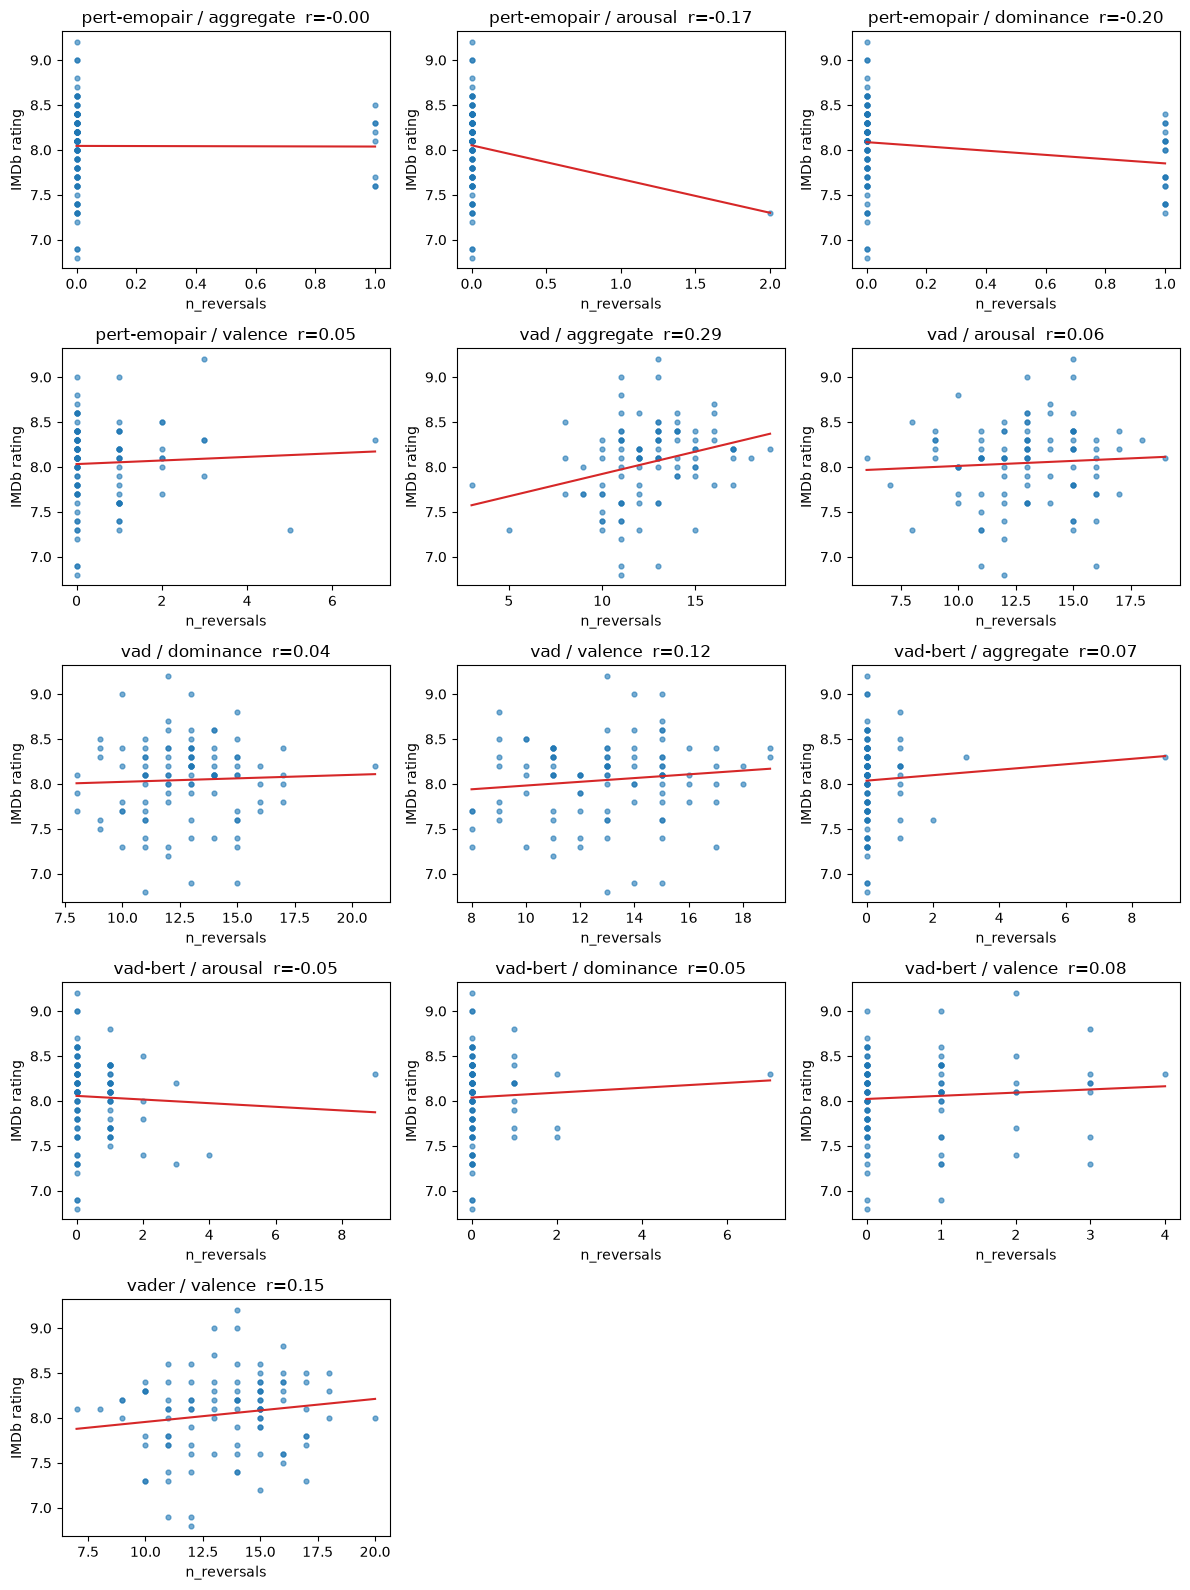

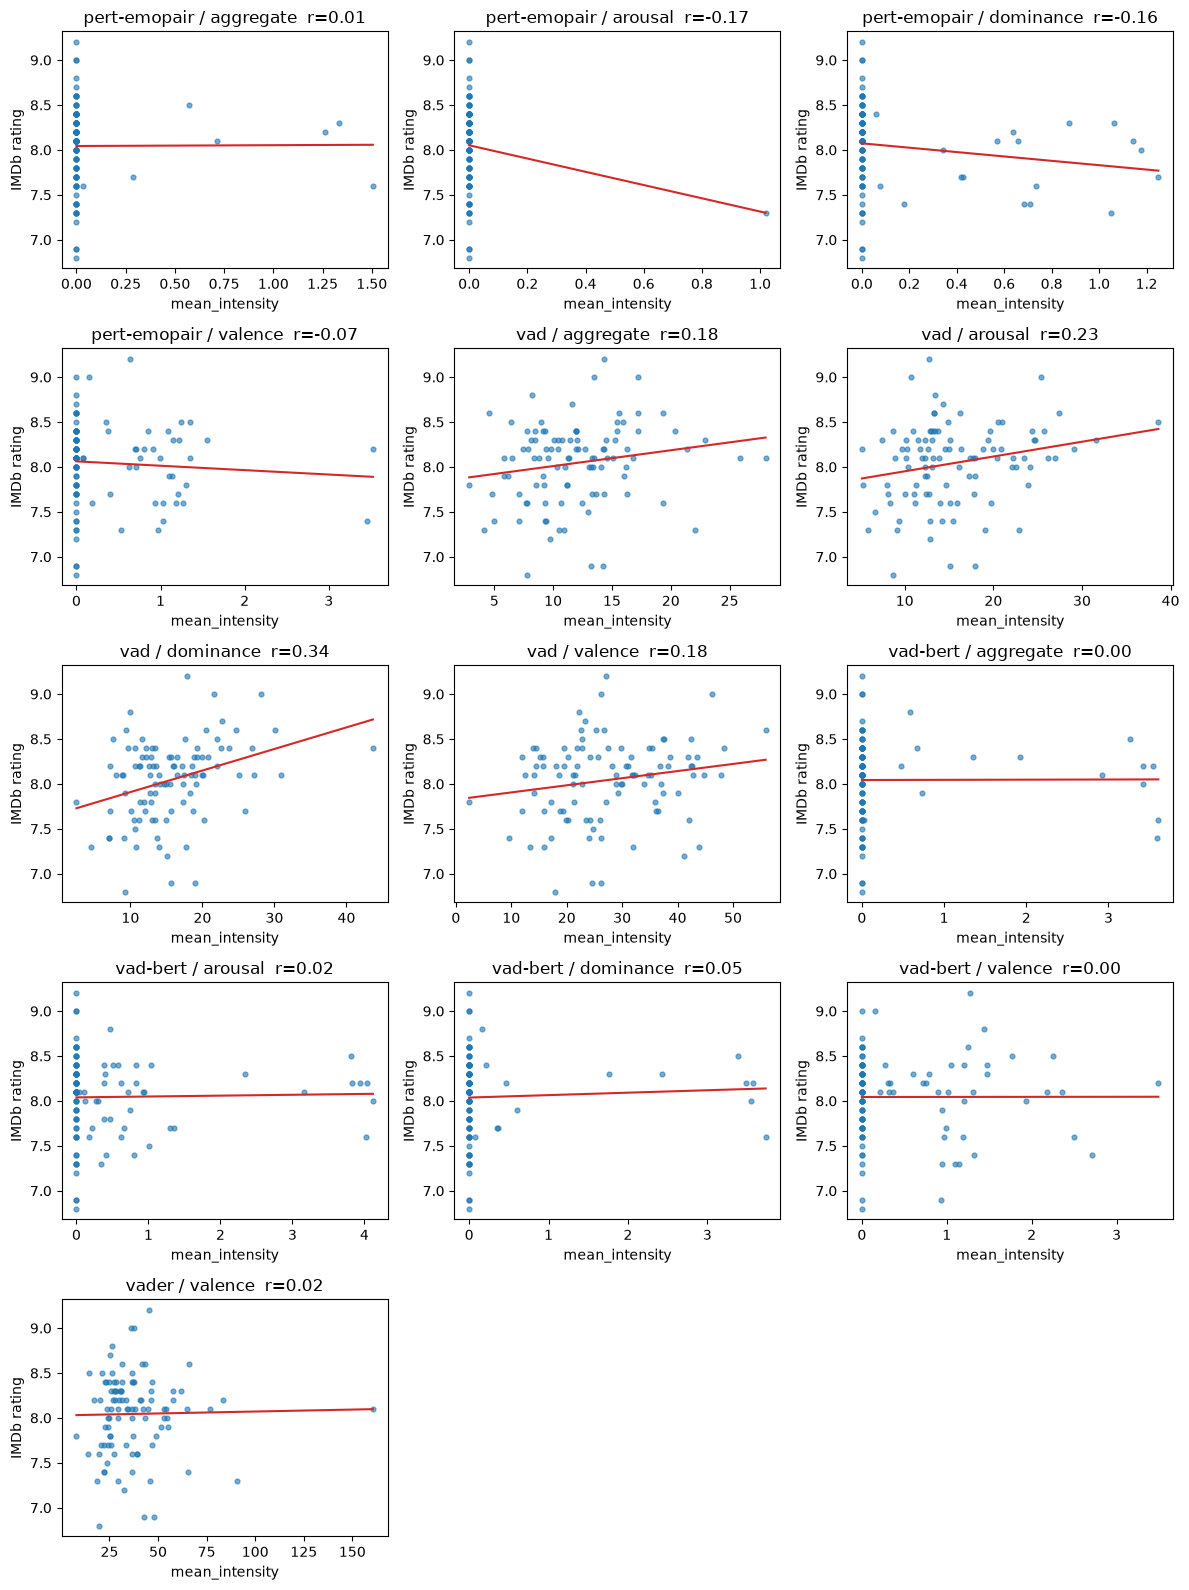

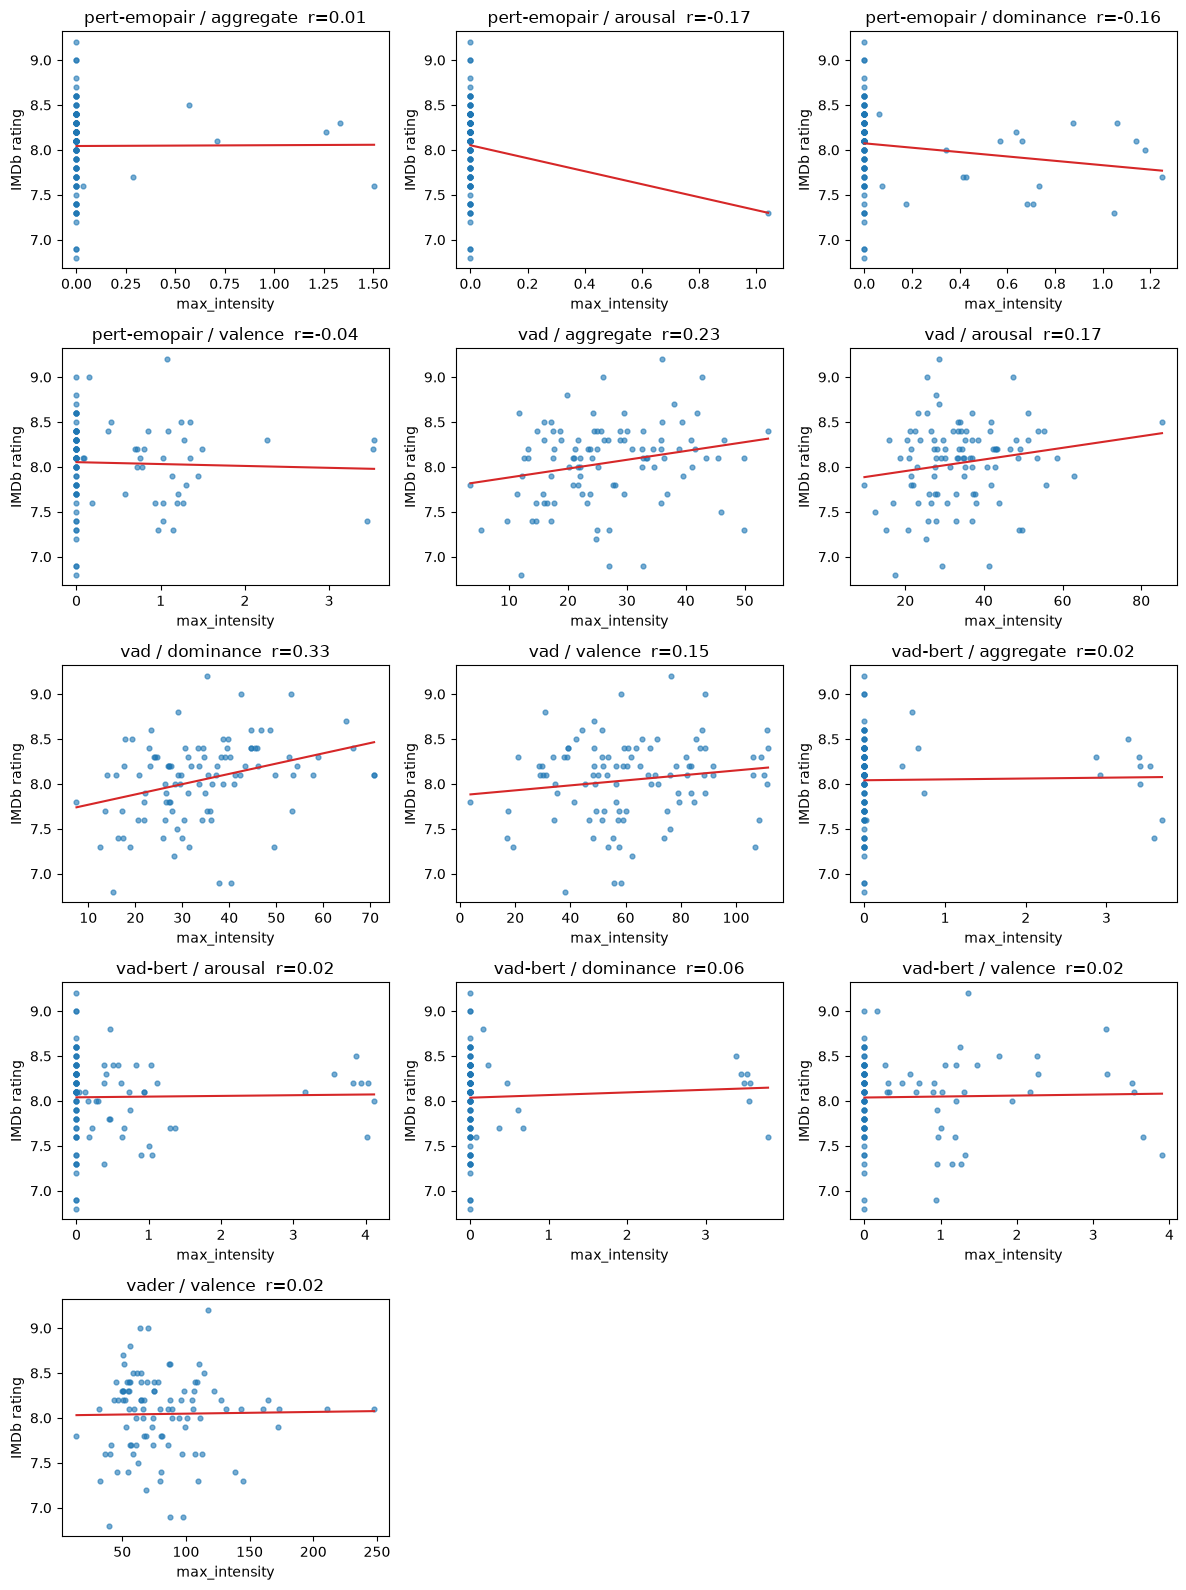

In [77]:
for feature in rr.FEATURES:
    rr.plot_feature_vs_rating(df, feature)

## Per-movie comparison (sorted by rating)

In [78]:
rr.movie_table(df, "n_reversals")

scorer_name                                                               pert-emopair  \
dimension                                                                    aggregate   
imdb_id_int primary_title                                  average_rating                
68646       The Godfather                                  9.2                     0.0   
71562       The Godfather Part II                          9.0                     0.0   
50083       12 Angry Men                                   9.0                     0.0   
60196       The Good, the Bad and the Ugly                 8.8                     0.0   
80684       Star Wars: Episode V - The Empire Strikes Back 8.7                     0.0   
...                                                                                ...   
79817       Rocky II                                       7.3                     0.0   
77631       Grease                                         7.2                     0.0   
89927       Rocky IV                                       6.9                     0.0   
84602       Rocky III                                      6.9                     0.0   
79501       Mad Max                                        6.8                     0.0   

scorer_name                                                                        \
dimension                                                                 arousal   
imdb_id_int primary_title                                  average_rating           
68646       The Godfather                                  9.2                0.0   
71562       The Godfather Part II                          9.0                0.0   
50083       12 Angry Men                                   9.0                0.0   
60196       The Good, the Bad and the Ugly                 8.8                0.0   
80684       Star Wars: Episode V - The Empire Strikes Back 8.7                0.0   
...                                                                           ...   
79817       Rocky II                                       7.3                0.0   
77631       Grease                                         7.2                0.0   
89927       Rocky IV                                       6.9                0.0   
84602       Rocky III                                      6.9                0.0   
79501       Mad Max                                        6.8                0.0   

scorer_name                                                                          \
dimension                                                                 dominance   
imdb_id_int primary_title                                  average_rating             
68646       The Godfather                                  9.2                  0.0   
71562       The Godfather Part II                          9.0                  0.0   
50083       12 Angry Men                                   9.0                  0.0   
60196       The Good, the Bad and the Ugly                 8.8                  0.0   
80684       Star Wars: Episode V - The Empire Strikes Back 8.7                  0.0   
...                                                                             ...   
79817       Rocky II                                       7.3                  0.0   
77631       Grease                                         7.2                  0.0   
89927       Rocky IV                                       6.9                  0.0   
84602       Rocky III                                      6.9                  0.0   
79501       Mad Max                                        6.8                  0.0   

scorer_name                                                                        \
dimension                                                                 valence   
imdb_id_int primary_title                                  average_rating           
68646       The Godfather                                  9.2            

In [79]:
rr.movie_table(df, "mean_intensity").round(3)

scorer_name                                                               pert-emopair  \
dimension                                                                    aggregate   
imdb_id_int primary_title                                  average_rating                
68646       The Godfather                                  9.2                     0.0   
71562       The Godfather Part II                          9.0                     0.0   
50083       12 Angry Men                                   9.0                     0.0   
60196       The Good, the Bad and the Ugly                 8.8                     0.0   
80684       Star Wars: Episode V - The Empire Strikes Back 8.7                     0.0   
...                                                                                ...   
79817       Rocky II                                       7.3                     0.0   
77631       Grease                                         7.2                     0.0   
89927       Rocky IV                                       6.9                     0.0   
84602       Rocky III                                      6.9                     0.0   
79501       Mad Max                                        6.8                     0.0   

scorer_name                                                                        \
dimension                                                                 arousal   
imdb_id_int primary_title                                  average_rating           
68646       The Godfather                                  9.2                0.0   
71562       The Godfather Part II                          9.0                0.0   
50083       12 Angry Men                                   9.0                0.0   
60196       The Good, the Bad and the Ugly                 8.8                0.0   
80684       Star Wars: Episode V - The Empire Strikes Back 8.7                0.0   
...                                                                           ...   
79817       Rocky II                                       7.3                0.0   
77631       Grease                                         7.2                0.0   
89927       Rocky IV                                       6.9                0.0   
84602       Rocky III                                      6.9                0.0   
79501       Mad Max                                        6.8                0.0   

scorer_name                                                                          \
dimension                                                                 dominance   
imdb_id_int primary_title                                  average_rating             
68646       The Godfather                                  9.2                  0.0   
71562       The Godfather Part II                          9.0                  0.0   
50083       12 Angry Men                                   9.0                  0.0   
60196       The Good, the Bad and the Ugly                 8.8                  0.0   
80684       Star Wars: Episode V - The Empire Strikes Back 8.7                  0.0   
...                                                                             ...   
79817       Rocky II                                       7.3                  0.0   
77631       Grease                                         7.2                  0.0   
89927       Rocky IV                                       6.9                  0.0   
84602       Rocky III                                      6.9                  0.0   
79501       Mad Max                                        6.8                  0.0   

scorer_name                                                                        \
dimension                                                                 valence   
imdb_id_int primary_title                                  average_rating           
68646       The Godfather                                  9.2            

## Fig. 1: trajectories of the highest- and lowest-rated movies

Purple = up trend, blue = down trend, red = reversal extrema. Change `movie_ids` to inspect any movie.

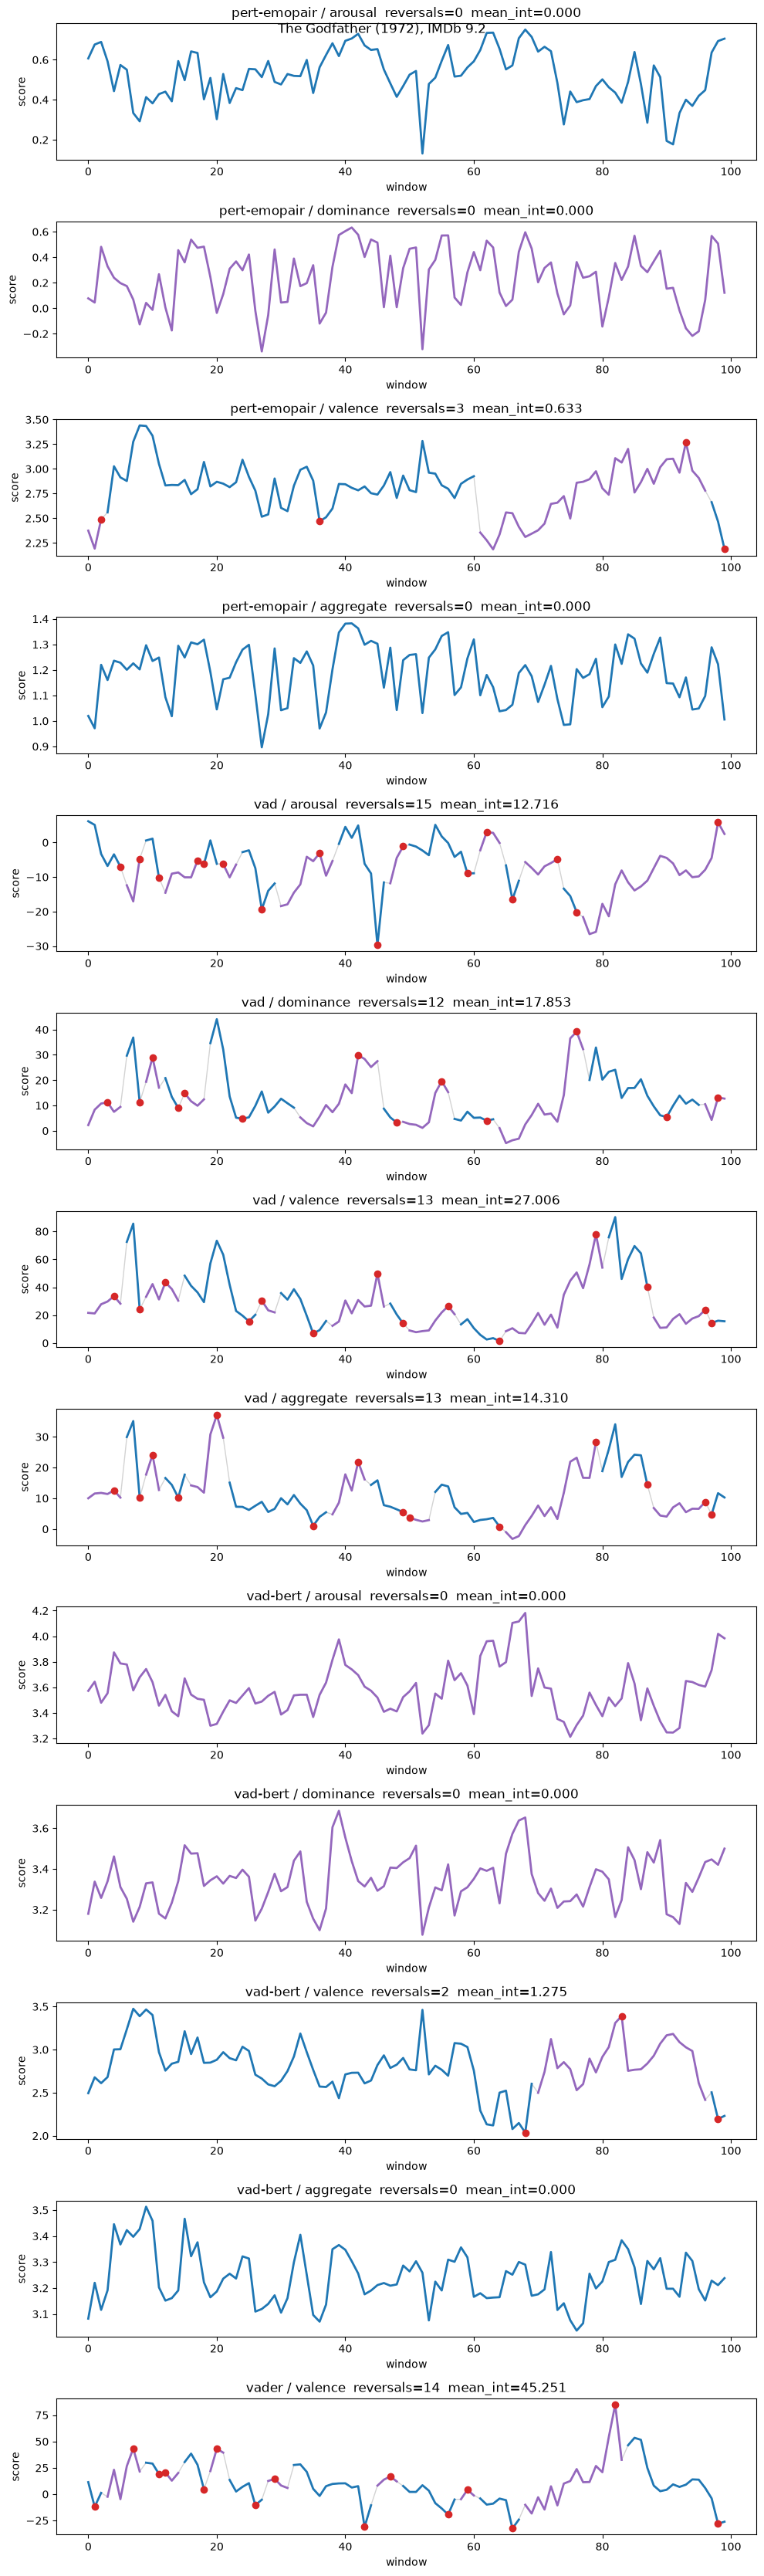

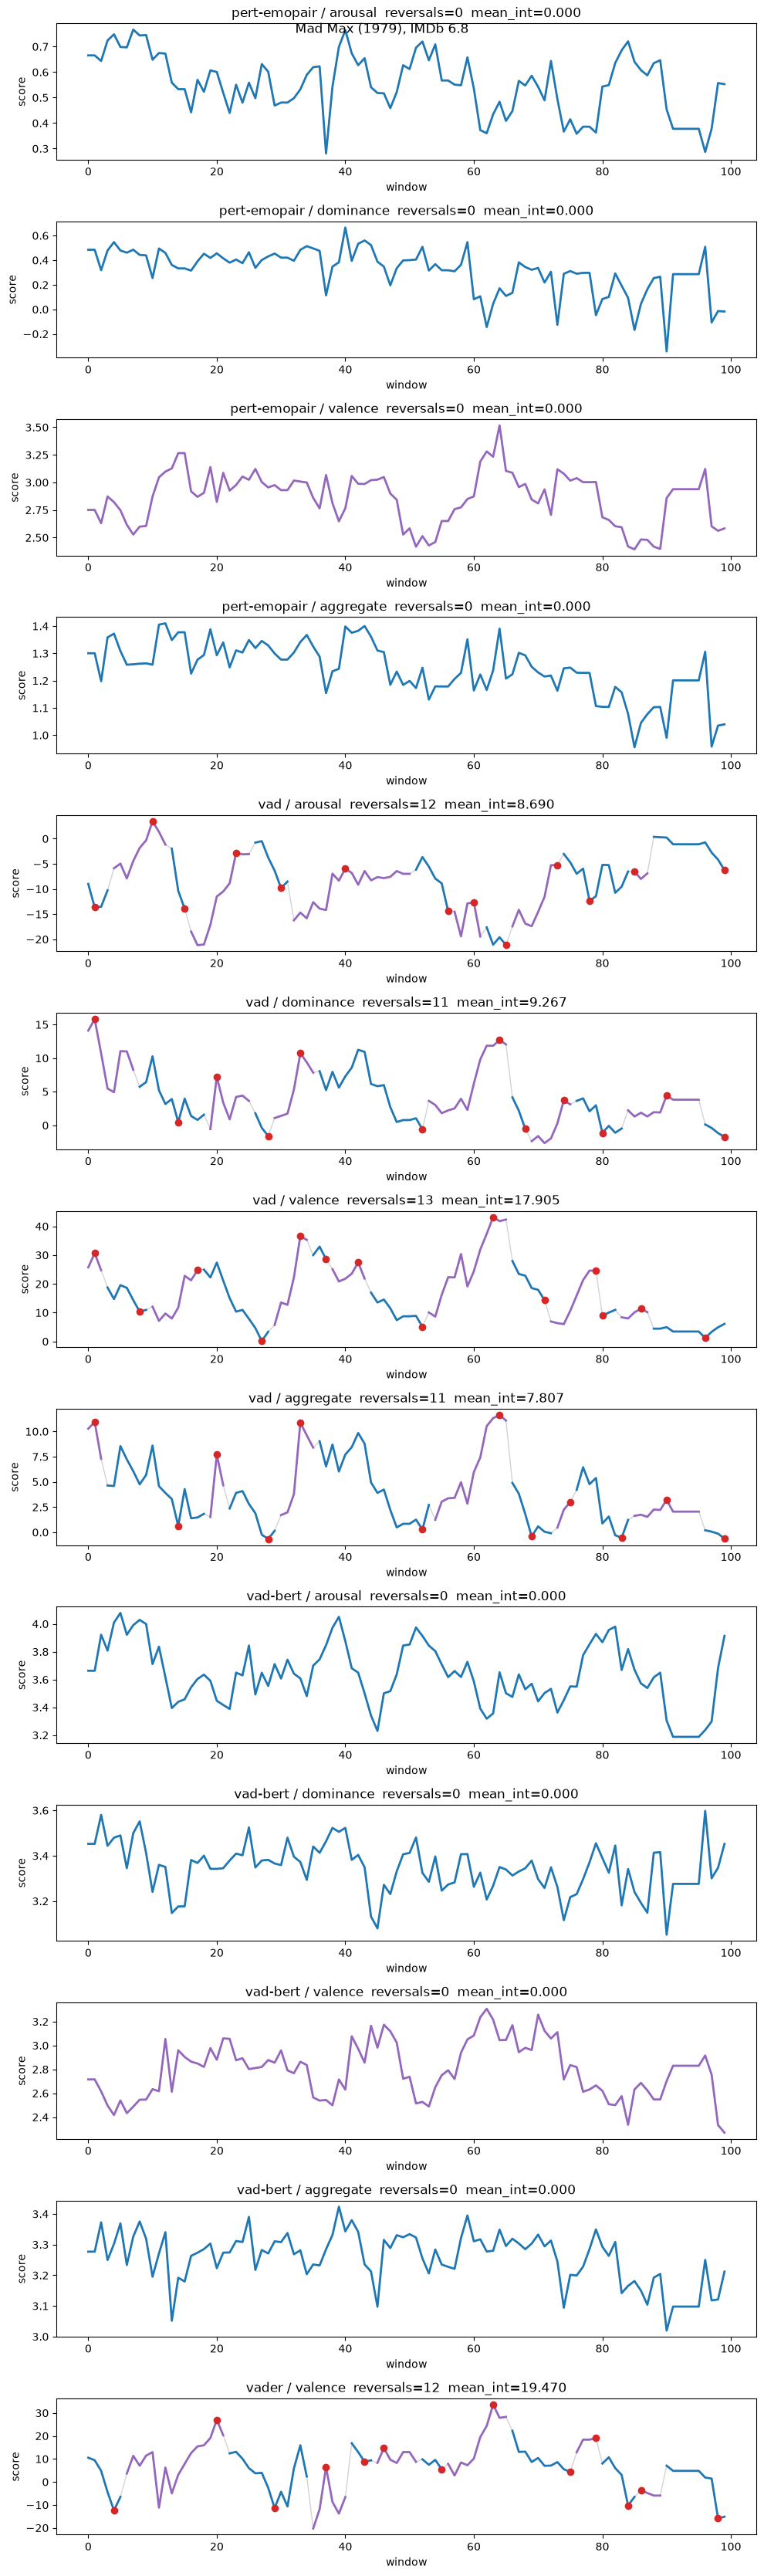

In [80]:
movies = df.drop_duplicates("imdb_id_int").set_index("imdb_id_int").sort_values(rr.RATING)
movie_ids = [movies.index[-1], movies.index[0]]

for imdb_id_int in movie_ids:
    m = movies.loc[imdb_id_int]
    rr.plot_movie(db, imdb_id_int, detector, title=f"{m.primary_title} ({m.start_year}), IMDb {m.average_rating}")